# Módulo 48: Interactividad

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m48-interactividad-guia.ipynb) y [solución](m48-interactividad-solucion.ipynb). No es una tarea entregada del programa.

Un informe estático responde las preguntas que su autor previó. Un tablero **interactivo** deja que el lector haga las suyas: elegir países, acotar un rango de fechas, pasar el cursor sobre una barra para ver el detalle o abrir la ficha de un país. En esta sección la interactividad la da **Streamlit**, y para usarla bien hay que entender primero cómo ejecuta el código. Esta lección recorre ese modelo de ejecución y después cada forma de interacción con el modelo de ventas de la práctica; todas se juntan en la app [`m48-interactividad-app.py`](m48-interactividad-app.py).

1. Del informe estático al tablero interactivo
2. El modelo de ejecución de Streamlit
3. Filtros en la barra lateral
4. Filtro cruzado entre gráficos
5. Jerarquías y exploración en profundidad
6. Obtener detalles: diálogos y enlaces profundos
7. Información sobre herramientas y minigráficos
8. Títulos dinámicos
9. La app completa, probada con AppTest
10. Errores frecuentes
11. Ejercicio

## 1. Del informe estático al tablero interactivo

Las herramientas de BI ofrecen un catálogo de objetos interactivos. En Streamlit y Plotly cada uno tiene un equivalente directo:

| Necesidad del lector | En una herramienta de BI | En Streamlit y Plotly |
| --- | --- | --- |
| Elegir qué datos ver | Segmentadores | Widgets en `st.sidebar`: `multiselect`, `pills`, `segmented_control`, `selectbox`, `slider` |
| Acotar un periodo | Segmentador de fechas "Entre" | `st.slider` sobre una tupla de fechas o `st.date_input` |
| Que un gráfico filtre a los demás | Interacciones entre visuales | `st.plotly_chart(fig, on_select=..., key=...)` y un filtro calculado con la selección |
| Bajar de categoría a producto | Jerarquías y explorar en profundidad | `px.treemap` o `px.sunburst` con `path=[...]`, o un selector de nivel |
| Ver la ficha de un elemento | Obtención de detalles (drill through) | `@st.dialog`, opcionalmente con `st.query_params` |
| Ver un dato al pasar el cursor | Información sobre herramientas | `hovertemplate` y `custom_data` en Plotly; `LineChartColumn` en tablas |
| Saber qué se está viendo | Título dinámico | Un f-string construido con el estado de los filtros |

La diferencia de fondo es que aquí la interactividad **se programa**: cada filtro es una variable de Python y cada gráfico se calcula con esas variables. Eso exige entender cuándo se ejecuta el código.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

import streamlit as st
from streamlit import config
from streamlit.logger import set_log_level
from streamlit.testing.v1 import AppTest

# Fuera de "streamlit run", Streamlit escribe avisos y trazas en stderr; aquí se silencian.
# Primero se lee la configuración, porque al leerla Streamlit vuelve a fijar el nivel de los avisos.
config.get_option("logger.level")
set_log_level("critical")
# Importar streamlit cambia la plantilla de Plotly a "streamlit", que solo se ve bien dentro de una app
pio.templates.default = "plotly"
APP = Path("m48-interactividad-app.py").resolve()  # AppTest necesita una ruta absoluta o relativa a quien lo llama

## 2. El modelo de ejecución de Streamlit

### 2.1 El script se vuelve a ejecutar entero en cada interacción

Una app de Streamlit es un script de Python normal. Cada vez que el lector toca un widget (elige un país, mueve un deslizador, hace clic en un botón), Streamlit **vuelve a ejecutar el script completo, de arriba abajo**, con el nuevo valor del widget. No hay funciones de "evento" que se llamen por separado: el widget devuelve su valor actual y el resto del script lo usa.

Esto tiene una consecuencia inmediata: las variables normales se reinician en cada ejecución. `AppTest` ejecuta una app sin navegador y permite comprobarlo. En este script, un botón suma 1 a una variable normal y a una entrada de `st.session_state`:

In [2]:
contador = r'''
import streamlit as st

st.session_state.setdefault("clics", 0)   # se inicializa una sola vez por sesión
clics_variable = 0                         # se reinicia en cada ejecución

if st.button("Sumar"):
    clics_variable += 1
    st.session_state.clics += 1

st.metric("Variable normal", clics_variable)
st.metric("st.session_state", st.session_state.clics)
'''

at = AppTest.from_string(contador).run()
for _ in range(3):
    at.button[0].click().run()   # cada clic provoca una nueva ejecución del script
[(m.label, m.value) for m in at.metric]

[('Variable normal', '1'), ('st.session_state', '3')]

Después de tres clics, la variable normal vale 1 (se puso a 0 al inicio de la última ejecución y el botón la subió a 1), mientras que `st.session_state` conserva el valor entre ejecuciones y llega a 3.

### 2.2 `st.session_state` y las `key` de los widgets

`st.session_state` es un diccionario por sesión (por pestaña del navegador) que sobrevive a las re-ejecuciones. Todo widget con `key` guarda ahí su valor: `st.multiselect("Países", PAISES, key="paises")` deja la selección en `st.session_state["paises"]`. Eso permite tres cosas que se usan en la app:

| Uso | Cómo |
| --- | --- |
| Dar un valor inicial a un widget | `st.session_state.setdefault("paises", PAISES)` **antes** de crear el widget |
| Cambiar un widget desde código (un botón "Restablecer") | Asignar `st.session_state["paises"]` dentro de un callback `on_click` |
| Leer una selección de un gráfico | `st.session_state["grafico_paises"]["selection"]` |

Los callbacks (`on_click`, `on_change`, `on_select`) se ejecutan **antes** de la nueva ejecución del script, por eso son el lugar para modificar el estado de un widget.

### 2.3 La caché: no repetir lo caro

Si cada interacción vuelve a ejecutar todo, también se repiten las consultas. Streamlit ofrece dos decoradores:

| Decorador | Para qué | En la app |
| --- | --- | --- |
| `@st.cache_resource` | Objetos compartidos que no se copian: conexiones, modelos | La conexión DuckDB, una sola para todas las sesiones |
| `@st.cache_data` | Resultados serializables (DataFrames, diccionarios); devuelve una copia | Cada consulta, indexada por sus argumentos |

`@st.cache_data` usa los argumentos como clave: con los mismos filtros devuelve el resultado guardado sin tocar la base. La conexión no se pasa como argumento (no se puede hashear); las funciones en caché la obtienen llamando a la función de `@st.cache_resource`. Los decoradores también funcionan fuera de `streamlit run`, así que se puede medir el efecto aquí mismo:

In [3]:
import time


@st.cache_data
def ventas_por_cache(columnas: tuple, filtros: dict) -> pd.DataFrame:
    return practica.ventas_por(con, list(columnas), **filtros)


filtros = {"paises": ("US", "CANADA"), "categorias": None, "desde": None, "hasta": None}
for intento in ("primera llamada", "segunda llamada"):
    inicio = time.perf_counter()
    ventas_por_cache(("categoria", "subcategoria", "producto"), filtros)
    print(f"{intento}: {(time.perf_counter() - inicio) * 1000:.1f} ms")

primera llamada: 131.0 ms
segunda llamada: 1.6 ms


La primera llamada consulta DuckDB; la segunda devuelve el resultado guardado en una fracción del tiempo. En una app con cinco o seis consultas por ejecución, la caché marca la diferencia entre un tablero que responde al instante y uno que se congela en cada clic.

## 3. Filtros en la barra lateral

Los filtros van en `st.sidebar` para dejar el área principal a los gráficos. El widget se elige según el número de opciones y el tipo de dato:

| Widget | Campo típico | Cuándo usarlo |
| --- | --- | --- |
| `st.multiselect` | Países (10 valores) | Varias opciones de una lista mediana o larga |
| `st.pills(..., selection_mode="multi")` | Categorías (3 valores) | Pocas opciones que conviene ver todas, como botones |
| `st.segmented_control` | Nivel de fecha: mes, trimestre, año | Una sola opción entre 2 y 5 |
| `st.selectbox` | Una tienda entre 200 | Una sola opción de una lista larga |
| `st.slider` con una tupla de fechas | Rango de fechas | Rango continuo con deslizador, como un segmentador "Entre" |
| `st.date_input` con una tupla | Rango de fechas | Cuando se prefiere un calendario |

El bloque de filtros de la app inicializa el estado en un solo lugar y crea los widgets sin `default`, porque el valor ya está en su `key`:

```python
st.session_state.setdefault("paises", PAISES)
st.session_state.setdefault("categorias", CATEGORIAS)
st.session_state.setdefault("fechas", (INICIO, FIN))

with st.sidebar:
    paises = st.multiselect("Países", PAISES, key="paises")
    categorias = st.pills("Categorías", CATEGORIAS, selection_mode="multi", key="categorias")
    desde, hasta = st.slider("Rango de fechas", min_value=INICIO, max_value=FIN,
                             format="DD/MM/YYYY", key="fechas")

filtros = {"paises": tuple(paises), "categorias": tuple(categorias), "desde": desde, "hasta": hasta}
```

Un deslizador cuyo valor es una **tupla** de dos fechas se convierte en un deslizador de rango con dos tiradores. Los filtros se guardan como tuplas para que el diccionario sea hashable y sirva de clave de caché. En el notebook, ese diccionario se pasa tal cual a las medidas de `ventas.py`:

In [4]:
import datetime as dt

filtros = {"paises": ("US", "CANADA"), "categorias": ("Technology",),
           "desde": dt.date(2020, 1, 1), "hasta": dt.date(2020, 12, 31)}
comparacion = pd.DataFrame({"sin filtros": practica.kpis(con), "con filtros": practica.kpis(con, **filtros)})
comparacion.map("{:,.0f}".format).replace(",", " ", regex=True)

,sin filtros,con filtros
ventas_total,41 940 958 825,721 438 071
cantidad_total,148 055 781,2 059 129
precio_mediana,218,351
ventas_promedio,27 979,17 226
transacciones,1 499 000,41 880


`AppTest` permite cambiar un widget y volver a ejecutar, como haría el lector. Este script mínimo usa el mismo patrón: un multiselect, el diccionario de filtros y una métrica.

In [5]:
mini_app = r'''
import sys
from pathlib import Path
import streamlit as st

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

@st.cache_resource
def conexion():
    return practica.conectar()

PAISES = ["US", "CANADA", "MEXICO"]
st.session_state.setdefault("paises", PAISES)
paises = st.sidebar.multiselect("Países", PAISES, key="paises")
resumen = practica.kpis(conexion(), paises=paises)
st.metric("Ventas", f"{resumen['ventas_total']:,}".replace(",", " "))
'''

at = AppTest.from_string(mini_app, default_timeout=60).run()
print("Tres países:", at.metric[0].value)
at.multiselect[0].set_value(["MEXICO"]).run()
print("Solo MEXICO:", at.metric[0].value)

Tres países: 16 364 381 054
Solo MEXICO: 4 655 551 012


## 4. Filtro cruzado entre gráficos

En una herramienta de BI, al hacer clic en una barra los demás visuales reaccionan. En Streamlit eso se activa con `on_select` en `st.plotly_chart`: el gráfico se comporta como un widget y devuelve la selección. Primero, el gráfico de países que usa la app:

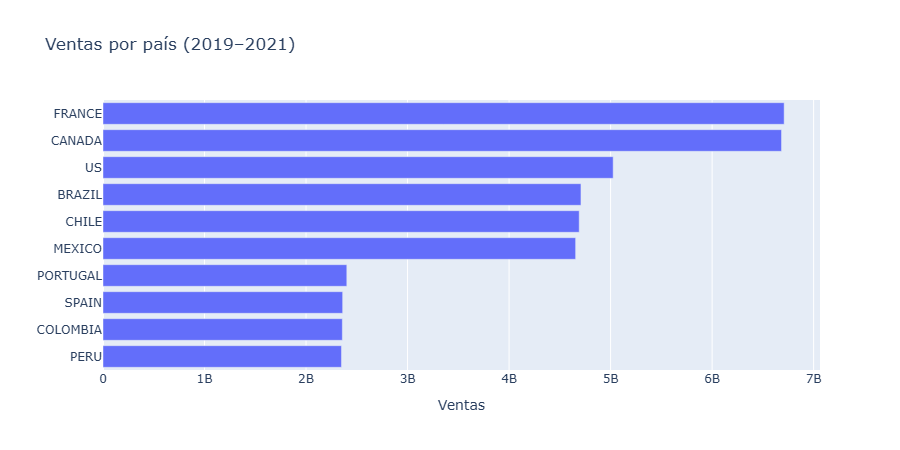

In [6]:
por_pais = practica.ventas_por(con, "pais").sort_values("ventas_total")
figura = px.bar(
    por_pais, x="ventas_total", y="pais", orientation="h",
    custom_data=["pais", "ventas_promedio", "transacciones", "cantidad_total"],
    labels={"ventas_total": "Ventas", "pais": ""}, title="Ventas por país (2019–2021)",
)
figura.update_layout(separators=", ")
figura.show()

En la app, el gráfico se muestra con una `key` y un callback de selección:

```python
evento = st.plotly_chart(
    figura,
    key="grafico_paises",          # la selección queda en st.session_state["grafico_paises"]
    on_select=al_seleccionar,      # o "rerun": vuelve a ejecutar sin callback
    selection_mode=("points", "box"),
)
seleccion = paises_de_seleccion(evento.selection, paises)
filtros_cruzados = {**filtros, "paises": tuple(seleccion)} if seleccion else filtros
```

Con `on_select="rerun"` (o un callback), `st.plotly_chart` devuelve un objeto parecido a un diccionario con la clave `selection`, que contiene `points` (los puntos elegidos, con `x`, `y` y `customdata`), `point_indices`, `box` y `lasso`. La misma información está en `st.session_state[key]`, que es lo que lee el callback.

El paso de la selección a una lista de países es **lógica pura**, sin Streamlit, y conviene escribirla como función aparte. Así se puede probar, porque `AppTest` **no puede simular** una selección en un gráfico (no hay forma de "hacer clic" en una barra desde la prueba). Se prueba con una selección construida a mano, con la misma forma que la que envía el navegador:

In [7]:
def pais_del_punto(punto: dict) -> str:
    # custom_data[0] es el país; en barras horizontales también está en "y"
    datos = punto.get("customdata")
    return datos[0] if datos else punto.get("y")


def paises_de_seleccion(seleccion, disponibles: list[str]) -> list[str] | None:
    # Países seleccionados en el orden de `disponibles`; None si no hay selección
    puntos = (seleccion or {}).get("points", [])
    elegidos = {pais_del_punto(punto) for punto in puntos}
    paises = [pais for pais in disponibles if pais in elegidos]
    return paises or None


def punto(pais):
    # Un punto como los que envía el navegador al seleccionar una barra
    fila = por_pais.set_index("pais").loc[pais]
    return {"curve_number": 0, "x": int(fila["ventas_total"]), "y": pais,
            "customdata": [pais, fila["ventas_promedio"], fila["transacciones"], fila["cantidad_total"]]}


todos = por_pais["pais"].tolist()
print(paises_de_seleccion({"points": [], "box": [], "lasso": []}, todos))
print(paises_de_seleccion({"points": [punto("US")]}, todos))
print(paises_de_seleccion({"points": [punto("PERU"), punto("US")]}, todos))
print(paises_de_seleccion({"points": [punto("US")]}, ["CANADA", "MEXICO"]))  # US ya no está en la barra lateral

None
['US']
['PERU', 'US']
None


Sin selección la función devuelve `None` (sin filtro cruzado), y si la barra lateral ya no incluye el país seleccionado, lo descarta. El filtro cruzado se aplica así en la app:

| Elemento | Filtros que recibe | Equivalente en una herramienta de BI |
| --- | --- | --- |
| Gráfico de países | `filtros` (solo la barra lateral) | El visual de origen no se filtra a sí mismo; Plotly atenúa las barras no seleccionadas, como "resaltar" |
| KPIs, treemap, serie temporal, tabla | `filtros_cruzados` | Interacción "filtrar" |
| Diálogo de detalle | `filtros` con el país del detalle | Página de detalle que mantiene los filtros |

Si un elemento debe quedarse fijo (la interacción "ninguno"), basta con pasarle `filtros` en lugar de `filtros_cruzados`. Comprobación con los datos: si se selecciona US, los KPIs pasan a ser los de US.

In [8]:
seleccion = paises_de_seleccion({"points": [punto("US")]}, todos)
filtros = {"paises": tuple(todos), "categorias": None, "desde": None, "hasta": None}
filtros_cruzados = {**filtros, "paises": tuple(seleccion)} if seleccion else filtros
total, us = practica.kpis(con, **filtros)["ventas_total"], practica.kpis(con, **filtros_cruzados)["ventas_total"]
print(f"Ventas de todos los países: {total:,} | con US seleccionado: {us:,} ({us / total:.1%})".replace(",", " "))

Ventas de todos los países: 41 940 958 825 | con US seleccionado: 5 025 305 951 (12.0%)


## 5. Jerarquías y exploración en profundidad

Una jerarquía va de lo general a lo particular: categoría → subcategoría → producto. Plotly la dibuja con `px.treemap` o `px.sunburst` y el argumento `path`; el lector **explora en profundidad** haciendo clic en un rectángulo (baja un nivel) y en la barra superior (sube). Primero, cuántos elementos hay en cada nivel:

In [9]:
{nivel: len(practica.ventas_por(con, columnas)) for nivel, columnas in {
    "categoria": ["categoria"],
    "subcategoria": ["categoria", "subcategoria"],
    "producto": ["categoria", "subcategoria", "producto"],
}.items()}

{'categoria': 3, 'subcategoria': 13, 'producto': 607}

Con cientos de productos, mostrar los tres niveles a la vez sería ilegible. En el notebook se dibujan los dos primeros; en la app se pasan los tres con `maxdepth=3` (contando la raíz "Todas"), de modo que se ven categorías y subcategorías y un clic en una subcategoría baja a sus productos.

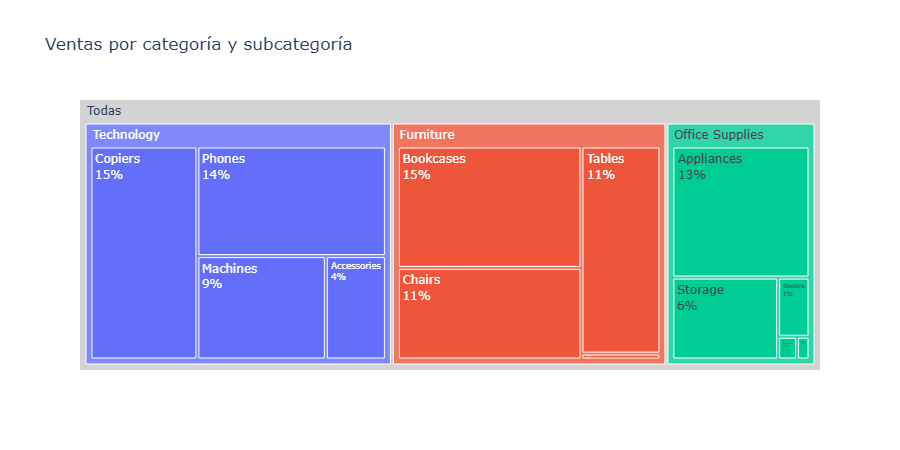

,categoria,subcategoria,ventas_total
0,Technology,Copiers,6383204325
1,Furniture,Bookcases,6278627615
2,Technology,Phones,5792285031
3,Office Supplies,Appliances,5263127221
4,Furniture,Chairs,4735431382


In [10]:
por_subcategoria = practica.ventas_por(con, ["categoria", "subcategoria"])
treemap = px.treemap(
    por_subcategoria, path=[px.Constant("Todas"), "categoria", "subcategoria"], values="ventas_total",
    title="Ventas por categoría y subcategoría",
)
treemap.update_traces(textinfo="label+percent root", root_color="lightgrey")
treemap.show()
por_subcategoria.head(5)[["categoria", "subcategoria", "ventas_total"]]

En la app:

```python
treemap = px.treemap(
    jerarquia,
    path=[px.Constant("Todas"), "categoria", "subcategoria", "producto"],
    values="ventas_total",
    maxdepth=3,  # se ven dos niveles; un clic en una subcategoría baja a sus productos
)
```

`px.sunburst` acepta los mismos argumentos y dibuja la jerarquía en anillos. La otra forma de explorar es un **selector de nivel**: un widget que cambia la columna por la que se agrupa. La app lo usa con la jerarquía de fechas, con un `st.segmented_control` que elige entre mes, trimestre y año para `serie_temporal`:

```python
NIVELES = {"month": "Mes", "quarter": "Trimestre", "year": "Año"}
nivel = st.segmented_control("Nivel de la fecha", list(NIVELES), format_func=NIVELES.get,
                             default="month", required=True, key="nivel")
evolucion = serie(nivel, filtros_cruzados)
```

Es el equivalente a "ir al siguiente nivel" de una jerarquía de fechas: cambia todo el eje a la vez.

In [11]:
{nivel: len(practica.serie_temporal(con, nivel)) for nivel in ("month", "quarter", "year")}

{'month': 36, 'quarter': 12, 'year': 3}

## 6. Obtener detalles: diálogos y enlaces profundos

La exploración en profundidad se queda en el mismo gráfico. **Obtener detalles** lleva a una vista aparte, filtrada por el elemento elegido: "muéstrame todo sobre Canadá". En Streamlit esa vista es un **diálogo modal**: una función decorada con `@st.dialog` que, al llamarla, abre una ventana encima del tablero.

```python
@st.dialog("Detalle del país", width="large", on_dismiss=cerrar_detalle)
def detalle_pais(pais: str, filtros: dict):
    # Mantiene categorías y fechas de la barra lateral; solo cambia el país
    filtros_pais = {**filtros, "paises": (pais,)}
    st.subheader(f"{pais}: productos más vendidos")
    resumen = kpis(filtros_pais)
    ...
    top = ventas_por(("categoria", "subcategoria", "producto"), filtros_pais).head(10)
    st.dataframe(top, ...)
    if st.button("Volver al tablero"):
        cerrar_detalle()
        st.rerun()
```

Pasar `filtros` al diálogo es el equivalente a "mantener todos los filtros": si el lector había acotado el rango a 2020, el detalle también es de 2020 y sus números coinciden con la barra en la que hizo clic.

¿Cuándo se abre? Si se llamara a `detalle_pais` siempre que haya una selección, el diálogo volvería a abrirse en cada re-ejecución mientras la barra siga seleccionada. La app lo resuelve en dos pasos:

1. El callback de selección, que solo se ejecuta cuando **cambia** la selección, guarda el país en la URL si se eligió uno solo: `st.query_params["detalle"] = "CANADA"`.
2. Al final del script, si la URL tiene un país válido, se abre el diálogo. Al cerrarlo (con la X, con Esc o con el botón), `cerrar_detalle` borra el parámetro.

```python
def al_seleccionar():
    seleccion = st.session_state["grafico_paises"]["selection"]
    elegidos = paises_de_seleccion(seleccion, PAISES)
    if elegidos and len(elegidos) == 1:
        st.query_params["detalle"] = elegidos[0]

pais_detalle = st.query_params.get("detalle")
if pais_detalle in PAISES:          # el valor viene de la URL: se valida antes de usarlo
    detalle_pais(pais_detalle, filtros)
```

Como el país queda en la URL, `…/?detalle=CANADA` es un **enlace profundo**: abre el tablero con el diálogo de Canadá ya abierto, y se puede compartir. Es lo que en una herramienta de BI se consigue con una URL con filtros. Para poner en la URL el valor de un widget completo, Streamlit tiene además `bind="query-params"` (junto con `key`), que sincroniza el widget con la URL sin escribir `st.query_params` a mano.

Los datos que muestra el diálogo, calculados aquí para Canadá en 2020:

In [12]:
filtros_detalle = {"paises": ["CANADA"], "desde": "2020-01-01", "hasta": "2020-12-31"}
top = practica.ventas_por(con, ["categoria", "subcategoria", "producto"], **filtros_detalle).head(10)
top[["producto", "categoria", "subcategoria", "ventas_total", "ventas_promedio"]].round(0)

,producto,categoria,subcategoria,ventas_total,ventas_promedio
0,"Motorola Smart Phone, Full Size",Technology,Phones,7876887,16208.0
1,"Nokia Smart Phone, Full Size",Technology,Phones,7113990,17436.0
2,"Apple Smart Phone, Full Size",Technology,Phones,6530551,16617.0
3,"Harbour Creations Executive Leather Armchair, ...",Furniture,Chairs,5829704,16468.0
4,"Hon Executive Leather Armchair, Adjustable",Furniture,Chairs,5641142,16072.0
5,"Cisco Smart Phone, Full Size",Technology,Phones,5495297,16909.0
6,"Novimex Executive Leather Armchair, Adjustable",Furniture,Chairs,5355135,17500.0
7,"Office Star Executive Leather Armchair, Adjust...",Furniture,Chairs,5336584,21518.0
8,"SAFCO Executive Leather Armchair, Adjustable",Furniture,Chairs,4405036,18509.0
9,"Cisco Smart Phone, with Caller ID",Technology,Phones,4351459,16866.0


Las tres formas de profundizar resuelven preguntas distintas:

| | Exploración en profundidad | Obtener detalles | Información sobre herramientas |
| --- | --- | --- | --- |
| Dónde ocurre | En el mismo gráfico | En un diálogo (o una página) aparte | Junto al cursor |
| Qué cambia | El nivel de la jerarquía | Toda la vista, filtrada por el elemento | Nada; solo se muestra información |
| En Streamlit y Plotly | `path` y `maxdepth` en treemap o sunburst; selector de nivel | `@st.dialog`, `st.query_params` | `hovertemplate`, `custom_data`, `LineChartColumn` |
| Pregunta típica | "¿Qué subcategorías hay en Furniture?" | "Muéstrame todo sobre Canadá" | "¿Cuánto vende de media este país?" |

## 7. Información sobre herramientas y minigráficos

Al pasar el cursor por un gráfico de Plotly aparece una etiqueta con los valores del punto. Se personaliza con dos piezas: `custom_data`, que adjunta columnas extra a cada punto, y `hovertemplate`, una plantilla donde `%{x}`, `%{y}` y `%{customdata[i]}` se sustituyen por los valores, con formato al estilo de Python (`:,.0f`). `<extra></extra>` quita la caja secundaria con el nombre de la serie.

In [13]:
figura.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Ventas: %{x:,.0f}<br>"
        "Venta promedio: %{customdata[1]:,.0f}<br>"
        "Transacciones: %{customdata[2]:,}<br>"
        "Unidades: %{customdata[3]:,}<extra></extra>"
    )
)
# La imagen PNG no muestra la etiqueta; estos son los datos que verá el lector sobre CANADA
fila = figura.data[0].y.tolist().index("CANADA")
print(figura.data[0].hovertemplate)
print(figura.data[0].customdata[fila])

<b>%{customdata[0]}</b><br>Ventas: %{x:,.0f}<br>Venta promedio: %{customdata[1]:,.0f}<br>Transacciones: %{customdata[2]:,}<br>Unidades: %{customdata[3]:,}<extra></extra>
['CANADA' 44736.36923519726 149398 14809154]


Las páginas de información sobre herramientas de una herramienta de BI muestran un minigráfico al pasar el cursor. En Streamlit, el equivalente más útil es un **minigráfico en cada fila de una tabla**: `st.column_config.LineChartColumn` dibuja una línea a partir de una lista de números por celda. Para la tabla por país, cada celda es la lista de unidades vendidas por mes:

In [14]:
mensual = practica.ventas_por(con, ["pais", "anio_mes"]).sort_values("anio_mes")
tendencia = mensual.groupby("pais")["cantidad_total"].agg(list).rename("cantidad_mensual")
tabla = practica.tabla_por_pais(con).merge(tendencia, on="pais")
print("Meses por país:", tabla["cantidad_mensual"].map(len).unique())
tabla[["pais", "ventas_total", "cantidad_mensual"]].head(3)

Meses por país: [36]


,pais,ventas_total,cantidad_mensual
0,FRANCE,6709452115,"[358166, 322318, 683010, 162705, 171933, 63580..."
1,CANADA,6683524091,"[356735, 327533, 655588, 159270, 168468, 62822..."
2,US,5025305951,"[364832, 320517, 651681, 163631, 167073, 64263..."


En la app, la columna se configura así:

```python
st.dataframe(
    tabla,
    hide_index=True,
    column_order=["pais", "ventas_total", "ventas_promedio", "pct_cantidad", "cantidad_mensual"],
    column_config={
        "pct_cantidad": st.column_config.NumberColumn("% de unidades", format="percent"),
        "cantidad_mensual": st.column_config.LineChartColumn("Unidades por mes", width="medium"),
    },
)
```

Las listas siguen el rango de fechas del filtro: con un solo año, cada minigráfico tiene 12 puntos.

## 8. Títulos dinámicos

Un tablero con filtros debe decir qué está mostrando. En una herramienta de BI se escribe una medida que devuelve texto; aquí basta un f-string construido con el estado de los filtros. La regla para listas largas es la misma que la de `SELECTEDVALUE` con un valor alternativo: si están todos, se dice "todos"; si son pocos, se nombran; si son muchos, se cuentan.

In [15]:
def lista_legible(elegidos, todos, todos_texto, unidad, maximo=3):
    elegidos = list(elegidos)
    if set(elegidos) == set(todos):
        return todos_texto
    if len(elegidos) > maximo:
        return f"{len(elegidos)} {unidad}"
    if len(elegidos) == 1:
        return elegidos[0]
    return ", ".join(elegidos[:-1]) + " y " + elegidos[-1]


def titulo_dinamico(paises, todos_paises, categorias, todas_categorias, desde, hasta):
    return (
        f"Ventas de {lista_legible(paises, todos_paises, 'todos los países', 'países')}"
        f" · {lista_legible(categorias, todas_categorias, 'todas las categorías', 'categorías')}"
        f" · del {desde:%d/%m/%Y} al {hasta:%d/%m/%Y}"
    )


CATEGORIAS = sorted(practica.ventas_por(con, "categoria")["categoria"])
inicio, fin = dt.date(2019, 1, 1), dt.date(2021, 12, 31)
print(titulo_dinamico(todos, todos, CATEGORIAS, CATEGORIAS, inicio, fin))
print(titulo_dinamico(["US", "CANADA"], todos, ["Technology"], CATEGORIAS, dt.date(2020, 1, 1), dt.date(2020, 12, 31)))
print(titulo_dinamico(todos[:5], todos, CATEGORIAS[:2], CATEGORIAS, inicio, fin))

Ventas de todos los países · todas las categorías · del 01/01/2019 al 31/12/2021
Ventas de US y CANADA · Technology · del 01/01/2020 al 31/12/2020
Ventas de 5 países · Furniture y Office Supplies · del 01/01/2019 al 31/12/2021


En la app, el título usa la selección del gráfico si la hay (`seleccion or paises`), así que también refleja el filtro cruzado. Como el título va arriba pero la selección se conoce más abajo, la app reserva su sitio con `cabecera = st.container()` antes de los gráficos y lo rellena al final con `with cabecera:`. Streamlit dibuja cada elemento en el contenedor donde se creó, no en el orden del código.

## 9. La app completa, probada con AppTest

[`m48-interactividad-app.py`](m48-interactividad-app.py) junta todas las piezas. Se lanza desde la raíz del repositorio:

```bash
uv run streamlit run s08-dashboards/m48-interactividad/m48-interactividad-app.py
```

| Sección del archivo | Qué hace |
| --- | --- |
| 1. Conexión y consultas en caché | `@st.cache_resource` para la conexión; `@st.cache_data` para cada consulta |
| 2. Funciones puras | `paises_de_seleccion`, `lista_legible`, `titulo_dinamico` (las de esta lección) |
| 3. Barra lateral | Países, categorías, rango de fechas y botón "Restablecer filtros" |
| 4. Filtro cruzado | Gráfico de países seleccionable con `hovertemplate` |
| 5. Jerarquía | Treemap categoría → subcategoría → producto |
| 6. Serie temporal | Línea con selector de nivel (mes, trimestre, año) |
| 7. Tabla por país | `LineChartColumn` con las unidades por mes |
| 8. Diálogo de detalle | `@st.dialog` abierto desde la selección o desde `?detalle=` |
| 9. Título y KPIs | Rellena el contenedor reservado arriba |

`AppTest` ejecuta el archivo sin navegador. Se puede leer cada elemento (`at.title`, `at.metric`, `at.dataframe`), cambiar widgets y volver a ejecutar:

In [16]:
def metricas(at):
    return {m.label: m.value for m in at.metric}


inicio_prueba = time.perf_counter()
at = AppTest.from_file(str(APP), default_timeout=60).run()
print(f"Primera ejecución: {time.perf_counter() - inicio_prueba:.1f} s | excepciones: {len(at.exception)}")
print(at.title[0].value)
metricas(at)

Primera ejecución: 2.7 s | excepciones: 0
Ventas de todos los países · todas las categorías · del 01/01/2019 al 31/12/2021


{'Ventas': '41 941,0 M',
 'Unidades': '148 055 781',
 'Transacciones': '1 499 000',
 'Venta promedio': '27 979'}

In [17]:
at.multiselect[0].set_value(["US", "CANADA"]).run()
print(at.title[0].value)
print(metricas(at))

at.pills[0].set_value(["Technology"]).run()
at.slider[0].set_range(dt.date(2020, 1, 1), dt.date(2020, 12, 31)).run()
print(at.title[0].value)
print(metricas(at))
assert not at.exception

Ventas de US y CANADA · todas las categorías · del 01/01/2019 al 31/12/2021
{'Ventas': '11 708,8 M', 'Unidades': '29 698 439', 'Transacciones': '299 827', 'Venta promedio': '39 052'}


Ventas de US y CANADA · Technology · del 01/01/2020 al 31/12/2020
{'Ventas': '721,4 M', 'Unidades': '2 059 129', 'Transacciones': '41 880', 'Venta promedio': '17 226'}


Cada cambio de widget vuelve a ejecutar el script y las métricas cambian en consecuencia. Las cifras coinciden con las de `practica.kpis` de la sección 3. El diálogo no se puede abrir con un clic en la prueba, pero sí con el enlace profundo, sembrando el parámetro de la URL:

In [18]:
at.query_params["detalle"] = "CANADA"
at.run()
print([s.value for s in at.subheader][-1])
print([(m.label, m.value) for m in at.metric][-3:])  # las tres métricas del diálogo
at.dataframe[-1].value[["producto", "ventas_total"]].head(3)

CANADA: productos más vendidos
[('Ventas', '359,1 M'), ('Unidades', '1 025 367'), ('Venta promedio', '17 154')]


,producto,ventas_total
0,"Motorola Smart Phone, Full Size",7876887
1,"Nokia Smart Phone, Full Size",7113990
2,"Apple Smart Phone, Full Size",6530551


El diálogo muestra Canadá con los filtros de categoría y fechas que había en la barra lateral (Technology, 2020). Por último, el botón "Restablecer filtros" (un callback que reasigna las `key` de los widgets) devuelve el tablero al estado inicial, y la segunda ejecución con los mismos filtros es mucho más rápida porque todas las consultas están en caché:

In [19]:
del at.query_params["detalle"]
at.button[0].click().run()
inicio_prueba = time.perf_counter()
at.run()
print(f"Ejecución con la caché llena: {time.perf_counter() - inicio_prueba:.2f} s")
print(at.title[0].value)
metricas(at)

Ejecución con la caché llena: 0.72 s
Ventas de todos los países · todas las categorías · del 01/01/2019 al 31/12/2021


{'Ventas': '41 941,0 M',
 'Unidades': '148 055 781',
 'Transacciones': '1 499 000',
 'Venta promedio': '27 979'}

Lo que `AppTest` no cubre (la selección en el gráfico, el clic en el treemap y el aspecto visual) se prueba de dos formas: la lógica, con funciones puras como `paises_de_seleccion`, y el resto, lanzando la app y usándola en el navegador.

## 10. Errores frecuentes

**Modificar el estado de un widget después de crearlo.** Asignar `st.session_state["paises"]` cuando el multiselect ya se dibujó en esta ejecución lanza una excepción. Se asigna antes de crear el widget o dentro de un callback (como hace el botón "Restablecer filtros"):

In [20]:
modificar_despues = r'''
import streamlit as st
paises = st.multiselect("Países", ["US", "CANADA"], default=["US"], key="paises")
st.session_state["paises"] = ["US", "CANADA"]   # demasiado tarde
'''
at_error = AppTest.from_string(modificar_despues).run()
print(at_error.exception[0].value.split(". ")[0])

`st.session_state['paises']` cannot be modified after the widget with that key is instantiated


**Olvidar `key`.** Dos widgets iguales sin `key` (por ejemplo, el mismo filtro en la barra lateral y en un diálogo) tienen el mismo identificador automático y la app falla. Sin `key` tampoco se puede leer la selección de un gráfico desde un callback, ni restablecer un filtro desde código:

In [21]:
sin_key = r'''
import streamlit as st
st.multiselect("Países", ["US", "CANADA"])
st.multiselect("Países", ["US", "CANADA"])
'''
at_error = AppTest.from_string(sin_key).run()
print(at_error.exception[0].value.splitlines()[0])

There are multiple `multiselect` elements with the same auto-generated ID. When this element is created, it is assigned an internal ID based on the element type and provided parameters. Multiple elements with the same type and parameters will cause this error.


**Recalcular todo sin caché.** Sin `@st.cache_data`, cada clic repite todas las consultas de la página, aunque los filtros no hayan cambiado (por ejemplo, al abrir el diálogo o cambiar el nivel de la serie). Este es el coste de las consultas de una sola ejecución de la app:

In [22]:
filtros = {"paises": None, "categorias": None, "desde": None, "hasta": None}
consultas = {
    "kpis": lambda: practica.kpis(con, **filtros),
    "por país": lambda: practica.ventas_por(con, "pais", **filtros),
    "jerarquía": lambda: practica.ventas_por(con, ["categoria", "subcategoria", "producto"], **filtros),
    "serie": lambda: practica.serie_temporal(con, "month", **filtros),
    "tabla": lambda: practica.tabla_por_pais(con, **filtros),
    "minigráficos": lambda: practica.ventas_por(con, ["pais", "anio_mes"], **filtros),
}
tiempos = {}
for nombre, consulta in consultas.items():
    inicio_c = time.perf_counter()
    consulta()
    tiempos[nombre] = round((time.perf_counter() - inicio_c) * 1000)
print(tiempos, "| total:", sum(tiempos.values()), "ms por ejecución")

{'kpis': 112, 'por país': 129, 'jerarquía': 248, 'serie': 136, 'tabla': 139, 'minigráficos': 173} | total: 937 ms por ejecución


Con la caché, ese coste solo se paga la primera vez que aparece cada combinación de filtros. Conviene limitar su tamaño (`max_entries`) para que no crezca sin control con muchas combinaciones, y añadir `ttl` si los datos cambian mientras la app está en marcha.

**Filtros que no llegan a todos los gráficos.** Si un gráfico se calcula con `filtros` en lugar de `filtros_cruzados` (o sin filtros), el tablero se contradice: los KPIs dicen una cosa y la línea otra. Aquí, con US seleccionado, una serie que olvidó el filtro cruzado:

In [23]:
filtros = {"paises": tuple(todos), "categorias": None, "desde": None, "hasta": None}
filtros_cruzados = {**filtros, "paises": ("US",)}
kpi = practica.kpis(con, **filtros_cruzados)["ventas_total"]
serie_mal = practica.serie_temporal(con, "month", **filtros)["ventas_total"].sum()
serie_bien = practica.serie_temporal(con, "month", **filtros_cruzados)["ventas_total"].sum()
print(f"KPI: {kpi:,} | serie sin el filtro cruzado: {serie_mal:,} | serie corregida: {serie_bien:,}".replace(",", " "))

KPI: 5 025 305 951 | serie sin el filtro cruzado: 41 940 958 825 | serie corregida: 5 025 305 951


La regla práctica: construir **un solo** diccionario de filtros por nivel (`filtros`, `filtros_cruzados`) y pasarlo a todas las consultas, en lugar de repetir los argumentos en cada llamada.

**Desempaquetar el rango de `st.date_input` antes de que esté completo.** Con un valor inicial de dos fechas, `st.date_input` es un selector de rango, pero mientras el lector elige, devuelve una tupla de **una** fecha. `desde, hasta = rango` falla en ese momento:

In [24]:
rango = (dt.date(2020, 3, 1),)   # lo que devuelve date_input tras el primer clic
try:
    desde, hasta = rango
except ValueError as error:
    print("Error:", error)

desde, hasta = rango if len(rango) == 2 else (rango[0], rango[0])  # o st.stop() hasta que haya dos fechas
print(desde, hasta)

Error: not enough values to unpack (expected 2, got 1)
2020-03-01 2020-03-01


`st.slider` con una tupla no tiene este problema, porque siempre devuelve las dos fechas.

**Tratar una selección vacía como "todo".** En `ventas.py`, `paises=[]` no deja pasar ninguna fila (es lo correcto para la seguridad por filas), así que un multiselect vaciado produce un tablero de ceros y promedios vacíos. La app lo detecta y se detiene con un aviso:

In [25]:
print(practica.kpis(con, paises=[]))

{'ventas_total': 0, 'cantidad_total': 0, 'precio_mediana': None, 'ventas_promedio': None, 'transacciones': 0}


```python
if not paises or not categorias:
    st.warning("Elige al menos un país y una categoría en la barra lateral.")
    st.stop()
```

**Abrir un diálogo en cada ejecución o dos diálogos a la vez.** Si `detalle_pais()` se llama con una condición que sigue siendo cierta en cada ejecución (por ejemplo, "hay una barra seleccionada"), el diálogo reaparece después de cerrarlo. Además, solo puede haber un diálogo abierto por ejecución:

In [26]:
dos_dialogos = r'''
import streamlit as st

@st.dialog("Detalle A")
def a():
    st.write("A")

@st.dialog("Detalle B")
def b():
    st.write("B")

a()
b()
'''
at_error = AppTest.from_string(dos_dialogos).run()
print(at_error.exception[0].value)

Only one dialog is allowed to be opened at the same time. Please make sure to not call a dialog-decorated function more than once in a script run.


## 11. Ejercicio

Se quiere una ficha de detalle por tienda, abierta desde un gráfico de barras de las tiendas que más venden.

1. Escribe `titulo_tienda(nombres)` que devuelva "Detalle de" y el nombre de la tienda si llega una sola, o "Detalle de varias tiendas" si llegan varias.
2. Calcula los datos de la ficha de una tienda: su tendencia mensual de ventas y una tabla de ventas por categoría, respetando un rango de fechas.
3. Decide si la ficha debe mantener el filtro de fechas del tablero.
4. Dibuja un gráfico de barras de las diez tiendas con más ventas cuya información sobre herramientas muestre el formato de la tienda (`A`, `AA` o `AAA`) y sus ventas de 2019, 2020 y 2021.
5. Construye una app mínima con un `st.selectbox` de tiendas y un botón que abra la ficha en un `@st.dialog`, y pruébala con `AppTest`.

Cuidado: el nombre de la tienda no es una clave. Agrupa por `id_tienda` y `tienda` a la vez.

### Solución

In [27]:
print(practica.ventas_por(con, ["id_tienda", "tienda"]).groupby("tienda")["id_tienda"].agg(list).loc[lambda s: s.map(len) > 1])

tienda
Schumm Inc    [40, 197]
Name: id_tienda, dtype: object


Dos tiendas distintas comparten nombre, así que agrupar solo por `tienda` sumaría sus ventas en una barra. Por eso todo se agrupa por `["id_tienda", "tienda"]` y el selector muestra el nombre seguido del número.

Paso 1, el título, con la misma regla que `lista_legible`:

In [28]:
def titulo_tienda(nombres):
    nombres = list(dict.fromkeys(nombres))   # sin repetidos, en orden
    return f"Detalle de {nombres[0]}" if len(nombres) == 1 else "Detalle de varias tiendas"


print(titulo_tienda(["Huels-Robel"]))
print(titulo_tienda(["Huels-Robel", "Schumm Inc"]))

Detalle de Huels-Robel
Detalle de varias tiendas


Paso 2. `ventas.py` no tiene un filtro por tienda, así que la ficha se calcula con SQL sobre la vista `ventas_detalle`, reutilizando `filtro_sql` para las fechas:

In [29]:
def ficha_tienda(con, id_tienda, desde=None, hasta=None):
    where, params = practica.filtro_sql(desde=desde, hasta=hasta)
    where = f"{where} AND id_tienda = ?" if where else "WHERE id_tienda = ?"
    params = [*params, id_tienda]
    mensual = con.cursor().execute(f'''
        SELECT anio_mes, CAST(sum(importe) AS BIGINT) AS ventas
        FROM ventas_detalle {where} GROUP BY anio_mes ORDER BY anio_mes
    ''', params).df()
    por_categoria = con.cursor().execute(f'''
        SELECT categoria, CAST(sum(importe) AS BIGINT) AS ventas, avg(importe) AS venta_promedio
        FROM ventas_detalle {where} GROUP BY categoria ORDER BY ventas DESC
    ''', params).df()
    return mensual, por_categoria


tiendas = practica.ventas_por(con, ["id_tienda", "tienda", "formato"])
primera = tiendas.iloc[0]
mensual, por_categoria = ficha_tienda(con, int(primera["id_tienda"]), "2020-01-01", "2020-12-31")
print(titulo_tienda([primera["tienda"]]), f"(tienda {primera['id_tienda']}, formato {primera['formato']}), año 2020")
print(len(mensual), "meses; total:", f"{mensual['ventas'].sum():,}".replace(",", " "))
por_categoria.round(0)

Detalle de Miller, D'Amore and Hammes (tienda 15, formato A), año 2020
12 meses; total: 23 710 768


,categoria,ventas,venta_promedio
0,Technology,10085931,9453.0
1,Furniture,8817571,9118.0
2,Office Supplies,4807266,8788.0


Paso 3: sí conviene mantener el filtro de fechas. Si el lector acotó el tablero a 2020, la ficha debe ser de 2020; de lo contrario sus números no coincidirían con la barra en la que hizo clic. Para que quede claro, la ficha muestra el periodo en su subtítulo.

Paso 4: el formato y las ventas por año viajan en `custom_data`. Las ventas por año se obtienen agrupando también por `anio` y pivotando:

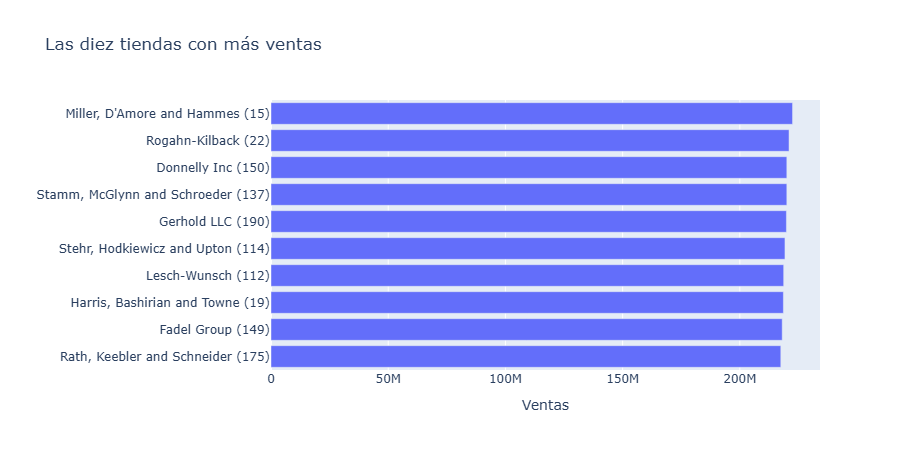

In [30]:
por_anio = (
    practica.ventas_por(con, ["id_tienda", "tienda", "formato", "anio"])
    .pivot_table(index=["id_tienda", "tienda", "formato"], columns="anio", values="ventas_total")
    .reset_index()
)
por_anio.columns = [str(c) for c in por_anio.columns]
por_anio["total"] = por_anio[["2019", "2020", "2021"]].sum(axis=1)
top_tiendas = por_anio.nlargest(10, "total").sort_values("total")
top_tiendas["etiqueta"] = top_tiendas["tienda"] + " (" + top_tiendas["id_tienda"].astype(str) + ")"

barras = px.bar(top_tiendas, x="total", y="etiqueta", orientation="h",
                custom_data=["formato", "2019", "2020", "2021"],
                labels={"total": "Ventas", "etiqueta": ""}, title="Las diez tiendas con más ventas")
barras.update_traces(hovertemplate=(
    "<b>%{y}</b> · formato %{customdata[0]}<br>"
    "2019: %{customdata[1]:,.0f}<br>2020: %{customdata[2]:,.0f}<br>2021: %{customdata[3]:,.0f}<extra></extra>"
))
barras.update_layout(separators=", ")
barras.show()

Paso 5: la app mínima. El `selectbox` guarda el `id_tienda` y muestra el nombre con `format_func`, así las dos "Schumm Inc" se distinguen. El diálogo recibe el rango de fechas del tablero.

In [31]:
app_tienda = r'''
import datetime as dt
import sys
from pathlib import Path
import streamlit as st

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

@st.cache_resource
def conexion():
    return practica.conectar()

@st.cache_data
def tiendas():
    return practica.ventas_por(conexion(), ["id_tienda", "tienda", "formato"])

@st.dialog("Ficha de la tienda", width="large")
def ficha(id_tienda, nombre, desde, hasta):
    st.subheader(f"Detalle de {nombre}")
    st.caption(f"Del {desde:%d/%m/%Y} al {hasta:%d/%m/%Y}")
    where, params = practica.filtro_sql(desde=desde, hasta=hasta)
    datos = conexion().cursor().execute(
        f"SELECT categoria, CAST(sum(importe) AS BIGINT) AS ventas FROM ventas_detalle {where} "
        "AND id_tienda = ? GROUP BY categoria ORDER BY ventas DESC", [*params, id_tienda]).df()
    st.metric("Ventas", f"{datos['ventas'].sum():,}".replace(",", " "))
    st.dataframe(datos, hide_index=True)

tabla = tiendas()
nombres = dict(zip(tabla["id_tienda"], tabla["tienda"]))
desde, hasta = st.sidebar.slider("Rango de fechas", min_value=dt.date(2019, 1, 1), max_value=dt.date(2021, 12, 31),
                                 value=(dt.date(2019, 1, 1), dt.date(2021, 12, 31)), key="fechas")
id_tienda = st.selectbox("Tienda", list(nombres), format_func=lambda i: f"{nombres[i]} ({i})", key="tienda")
if st.button("Ver ficha"):
    ficha(id_tienda, nombres[id_tienda], desde, hasta)
'''

at_tienda = AppTest.from_string(app_tienda, default_timeout=60).run()
at_tienda.slider[0].set_range(dt.date(2020, 1, 1), dt.date(2020, 12, 31))
at_tienda.selectbox[0].set_value(int(primera["id_tienda"]))
at_tienda.button[0].click().run()
print(at_tienda.subheader[0].value, "|", at_tienda.caption[0].value, "|", at_tienda.metric[0].value)
at_tienda.dataframe[0].value

Detalle de Miller, D'Amore and Hammes | Del 01/01/2020 al 31/12/2020 | 23 710 768


,categoria,ventas
0,Technology,10085931
1,Furniture,8817571
2,Office Supplies,4807266


La ficha de la tienda en 2020 coincide con la calculada en el paso 2 (mismas ventas por categoría), lo que confirma que el diálogo mantiene el filtro de fechas. En una herramienta de BI habría que ocultar la página de detalle para que no apareciera en la navegación; un diálogo no ocupa ninguna página, así que ese paso desaparece.

## Resumen

- Streamlit vuelve a ejecutar el script entero en cada interacción; `st.session_state` guarda lo que debe sobrevivir y la caché (`cache_resource` para la conexión, `cache_data` para las consultas) evita repetir lo caro.
- Los filtros son widgets en `st.sidebar` con `key`; se inicializan en un solo lugar y se reúnen en un diccionario que llega a todas las consultas.
- `st.plotly_chart(..., on_select=..., key=...)` convierte un gráfico en un filtro; la lógica de la selección se escribe como función pura y se prueba sin navegador.
- `path` y `maxdepth` en un treemap dan la exploración en profundidad; un `segmented_control` hace de selector de nivel.
- `@st.dialog` muestra el detalle sin salir del tablero y, con `st.query_params`, se convierte en un enlace profundo.
- `hovertemplate` con `custom_data`, `LineChartColumn` y los títulos dinámicos hacen que cada elemento explique lo que muestra.
- `AppTest` prueba los widgets y las métricas; las selecciones en gráficos se cubren con funciones puras y con una prueba manual en el navegador.

En el **Módulo 49** se aplican principios de diseño a este tablero: jerarquía visual, disposición, color y navegación entre páginas.